# Assignment 5 - S22 Drawdown-Controlled Portfolio

Liquid Swiss equity basket with a monthly SPI drawdown exposure overlay.

## 1. Imports and Paths

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt


def find_course_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'market_data.parquet').exists() and (candidate / 'src').exists():
            return candidate
        nested = candidate / 'qpmwp-course'
        if (nested / 'data' / 'market_data.parquet').exists() and (nested / 'src').exists():
            return nested
    raise FileNotFoundError('Could not locate qpmwp-course.')


COURSE_ROOT = find_course_root()
DATA_PATH = COURSE_ROOT / 'data'
SRC_PATH = COURSE_ROOT / 'src'

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print('COURSE_ROOT:', COURSE_ROOT)
print('DATA_PATH:', DATA_PATH)

COURSE_ROOT: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course
DATA_PATH: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/data


In [2]:
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from optimization.optimization import Optimization, Objective
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)

## 2. Data

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3. Parameters

In [4]:
START_DATE = '2003-01-01'
BASE_REBALANCE_MONTHS = 3

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000
RISK_LOOKBACK_DAYS = 252 * 2
MAX_VOL_PERCENTILE = 0.90
MAX_STOCK_WEIGHT = 0.10

DRAWDOWN_THRESHOLD_1 = -0.10
DRAWDOWN_THRESHOLD_2 = -0.20
HIGH_EQUITY_EXPOSURE = 1.00
MID_EQUITY_EXPOSURE = 0.70
LOW_EQUITY_EXPOSURE = 0.50

print('Drawdown thresholds:', DRAWDOWN_THRESHOLD_1, DRAWDOWN_THRESHOLD_2)
print('Exposure levels:', HIGH_EQUITY_EXPOSURE, MID_EQUITY_EXPOSURE, LOW_EQUITY_EXPOSURE)

Drawdown thresholds: -0.1 -0.2
Exposure levels: 1.0 0.7 0.5


## 4. Builder Functions

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RETURN_HISTORY_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= kwargs.get('min_obs', MIN_RETURN_OBS)).astype(int),
    })


def bibfn_selection_volatility_cap(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RISK_LOOKBACK_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    vol = ret.std(axis=0) * np.sqrt(252)
    threshold = vol.quantile(kwargs.get('max_percentile', MAX_VOL_PERCENTILE))

    return pd.DataFrame({
        'values': vol,
        'binary': vol.le(threshold).fillna(False).astype(int),
    })


def cap_and_redistribute(weights, cap):
    weights = weights.copy().astype(float)
    if weights.empty:
        return weights
    if len(weights) * cap < 1:
        return weights / weights.sum()

    free = pd.Index(weights.index)
    capped = pd.Series(0.0, index=weights.index)
    remaining = 1.0

    while len(free) > 0:
        scaled = weights.loc[free] / weights.loc[free].sum() * remaining
        over = scaled > cap
        if not over.any():
            capped.loc[free] = scaled
            break
        capped.loc[scaled[over].index] = cap
        remaining = 1.0 - capped.sum()
        free = scaled[~over].index

    return capped / capped.sum()


class BaseInverseVolatilityPortfolio(Optimization):
    def __init__(self, max_weight=MAX_STOCK_WEIGHT, **kwargs):
        super().__init__(max_weight=max_weight, solver_name='no-solver-used', **kwargs)

    def set_objective(self, optimization_data):
        ret = optimization_data['return_series']
        vol = ret.std(axis=0) * np.sqrt(252)
        inv_vol = 1 / vol.replace(0, np.nan)
        self.objective = Objective(raw_weight=inv_vol.dropna())

    def solve(self):
        raw_weight = self.objective.coefficients['raw_weight']
        weights = raw_weight / raw_weight.sum()
        weights = cap_and_redistribute(weights, self.params['max_weight'])
        self.results.update({'weights': weights.to_dict(), 'status': True})
        return None


class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## 5. Rebalancing and Drawdown Dates

In [6]:
market_dates = data.market_data.index.get_level_values('date').unique().sort_values()
market_dates = pd.DatetimeIndex(market_dates)
market_dates = market_dates[(market_dates > pd.Timestamp(START_DATE)) & (market_dates <= market_dates.max())]

monthly_dates = pd.Series(market_dates, index=market_dates).groupby(market_dates.to_period('M')).max()
base_rebdates = monthly_dates.iloc[::BASE_REBALANCE_MONTHS].dt.strftime('%Y-%m-%d').tolist()
drawdown_signal_dates = monthly_dates.dt.strftime('%Y-%m-%d').tolist()

print('Base rebalances:', len(base_rebdates), base_rebdates[0], 'to', base_rebdates[-1])
print('Drawdown signal dates:', len(drawdown_signal_dates), drawdown_signal_dates[0], 'to', drawdown_signal_dates[-1])

Base rebalances: 86 2003-01-31 to 2024-04-30
Drawdown signal dates: 256 2003-01-31 to 2024-04-30


## 6. Base Portfolio

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
    'volatility_cap': SelectionItemBuilder(
        bibfn=bibfn_selection_volatility_cap,
        width=RISK_LOOKBACK_DAYS,
        max_percentile=MAX_VOL_PERCENTILE,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=RISK_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
}

optimization = BaseInverseVolatilityPortfolio(max_weight=MAX_STOCK_WEIGHT)

bs_s22_base = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=base_rebdates,
    quiet=True,
)

bt_s22_base = Backtest()
bt_s22_base.run(bs=bs_s22_base)

weights_s22_base = bt_s22_base.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s22_base.shape)
print('Average holdings:', weights_s22_base.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s22_base.max(axis=1).mean().round(3))

Backtest completed.
Weight matrix: (86, 166)
Average holdings: 79.9
Average max stock weight: 0.041


## 7. Drawdown Overlay

In [8]:
def build_drawdown_signal(spi_returns, signal_dates):
    spi_level = (1 + spi_returns.dropna()).cumprod()
    spi_peak = spi_level.cummax()
    spi_drawdown = spi_level / spi_peak - 1

    rows = []
    for date in pd.to_datetime(signal_dates):
        available = spi_drawdown.loc[spi_drawdown.index <= date]
        if available.empty:
            continue
        signal_day = available.index[-1]
        dd = spi_drawdown.loc[signal_day]
        if dd > DRAWDOWN_THRESHOLD_1:
            exposure = HIGH_EQUITY_EXPOSURE
        elif dd > DRAWDOWN_THRESHOLD_2:
            exposure = MID_EQUITY_EXPOSURE
        else:
            exposure = LOW_EQUITY_EXPOSURE
        rows.append({
            'signal_date': date,
            'signal_day': signal_day,
            'spi_level': spi_level.loc[signal_day],
            'spi_drawdown': dd,
            'equity_exposure': exposure,
        })

    signal = pd.DataFrame(rows).set_index('signal_date')
    return signal


drawdown_signal = build_drawdown_signal(data.bm_series, drawdown_signal_dates)
drawdown_signal.tail()

Out[0]: 
            signal_day  spi_level  spi_drawdown  equity_exposure
signal_date                                                     
2023-12-31  2023-12-31   3.240126     -0.119689              0.7
2024-01-31  2024-01-31   3.285326     -0.107408              0.7
2024-02-29  2024-02-29   3.303828     -0.102381              0.7
2024-03-31  2024-03-31   3.433945     -0.067030              1.0
2024-04-30  2024-04-30   3.350298     -0.089756              1.0


In [9]:
return_series = data.get_return_series(weekdays_only=False)

base_gross_returns = bt_s22_base.strategy.simulate(
    return_series=return_series,
    fc=0,
    vc=0,
)
base_gross_returns.name = 'S22 base gross'

base_net_returns = bt_s22_base.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
base_net_returns.name = 'S22 base net'

exposure_daily = drawdown_signal['equity_exposure'].reindex(base_gross_returns.index, method='ffill').fillna(HIGH_EQUITY_EXPOSURE)

fixed_cost = pd.Series(0.0, index=base_gross_returns.index)
if len(fixed_cost) > 1:
    n_days = (fixed_cost.index[1:] - fixed_cost.index[:-1]).to_numpy().astype('timedelta64[D]').astype(int)
    fixed_cost.iloc[1:] = (1 + FIXED_COSTS) ** (n_days / 252) - 1

base_turnover_cost = pd.Series(0.0, index=base_gross_returns.index)
base_turnover = bt_s22_base.strategy.turnover(return_series=return_series, rescale=False)
for date, turnover in base_turnover.items():
    date = pd.to_datetime(date)
    target = base_turnover_cost.index[base_turnover_cost.index >= date]
    if len(target) > 0:
        target_date = target[0]
        base_turnover_cost.loc[target_date] += turnover * VARIABLE_COSTS * exposure_daily.loc[target_date]

exposure_cost = exposure_daily.diff().abs().fillna(0) * VARIABLE_COSTS

s22_drawdown_gross_returns = base_gross_returns * exposure_daily
s22_drawdown_gross_returns.name = 'S22 drawdown gross'

s22_drawdown_net_returns = s22_drawdown_gross_returns - fixed_cost - base_turnover_cost - exposure_cost
s22_drawdown_net_returns.name = 'S22 drawdown net'

comparison = pd.concat(
    {
        'S22 drawdown net': s22_drawdown_net_returns,
        'S22 drawdown gross': s22_drawdown_gross_returns,
        'S22 base net': base_net_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)
print('Average equity exposure:', exposure_daily.loc[comparison.index].mean().round(3))
print('Exposure changes:', int(exposure_daily.diff().abs().gt(0).sum()))
print('Average overlay cost per day:', (fixed_cost + base_turnover_cost + exposure_cost).loc[comparison.index].mean().round(6))

2003-02-03 to 2024-04-30
                     count      mean       std  ...       50%       75%       max
S22 drawdown net    5609.0  0.000216  0.006516  ...  0.000315  0.003400  0.050009
S22 drawdown gross  5609.0  0.000278  0.006516  ...  0.000366  0.003455  0.050048
S22 base net        5609.0  0.000302  0.008416  ...  0.000451  0.004583  0.071458
SPI                 5609.0  0.000332  0.009932  ...  0.000350  0.005263  0.105788

[4 rows x 8 columns]
Average equity exposure: 0.786
Exposure changes: 30
Average overlay cost per day: 6.2e-05


/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


<ipython-input-1-fcc1e611f395>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


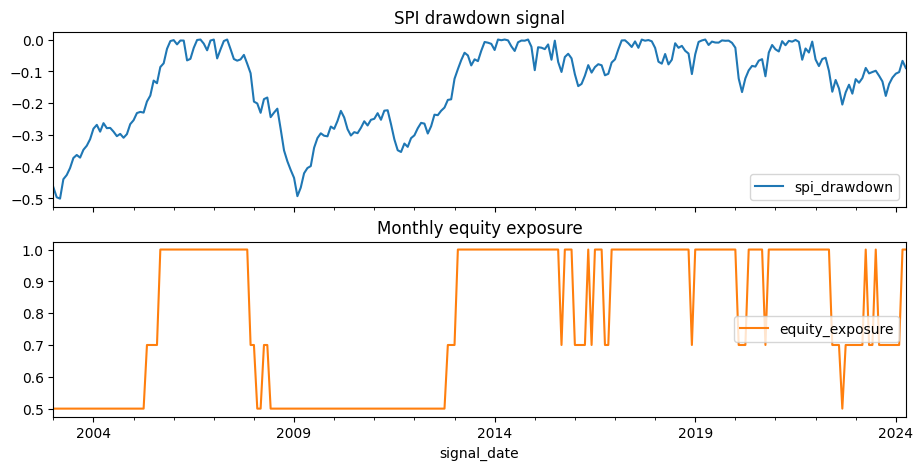

In [10]:
ax = drawdown_signal[['spi_drawdown', 'equity_exposure']].plot(
    subplots=True,
    figsize=(11, 5),
    title=['SPI drawdown signal', 'Monthly equity exposure'],
)
plt.show()

## 8. Returns

<ipython-input-1-e4b0e6297caf>:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


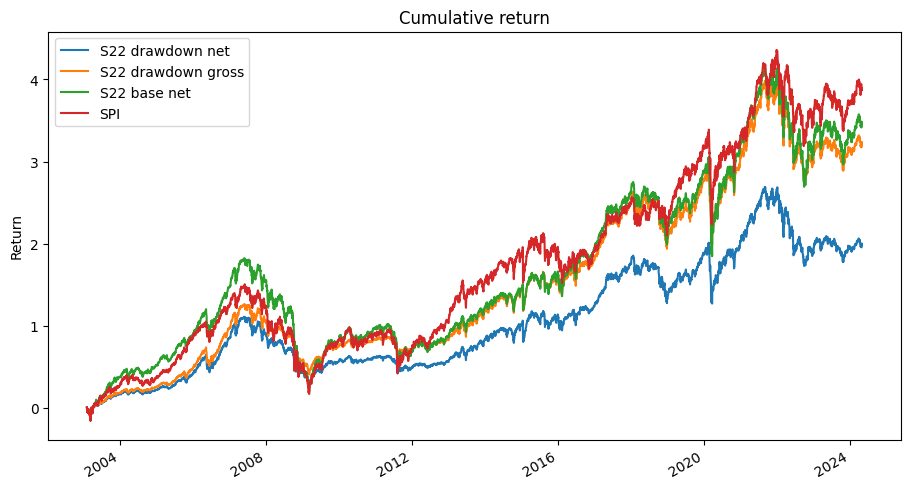

In [11]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Return')
plt.show()

<ipython-input-1-46ee3a3616a8>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


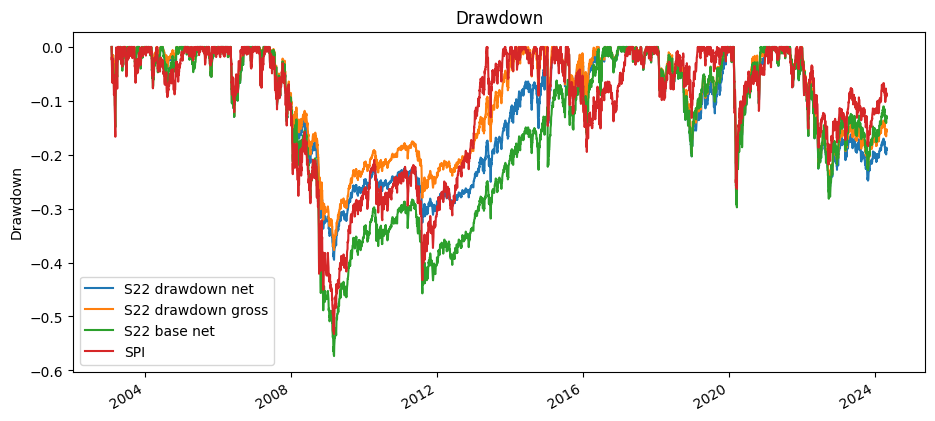

In [12]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    peak = wealth.cummax()
    return wealth / peak - 1


ax = drawdown(comparison).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
plt.show()

<ipython-input-1-fafb2b3115db>:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


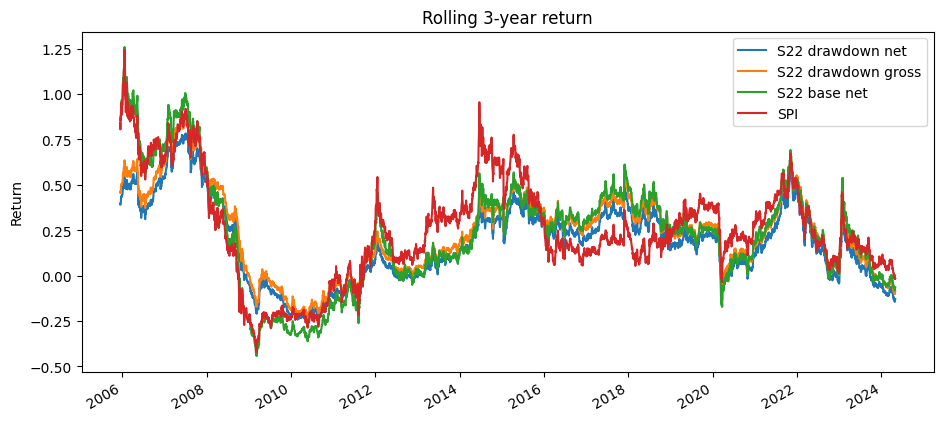

In [13]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return.plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Return')
plt.show()

## 9. Statistics

In [14]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

Out[0]: <pandas.io.formats.style.Styler at 0x15cfeaba0>


In [15]:
turnover_base = bt_s22_base.strategy.turnover(return_series=return_series, rescale=False)
exposure_turnover = exposure_daily.diff().abs().dropna()

print('Base average turnover:', turnover_base.mean().round(3))
print('Base median turnover:', turnover_base.median().round(3))
print('Average positive exposure change:', exposure_turnover[exposure_turnover > 0].mean().round(3))

pd.concat(
    {
        'base_turnover': turnover_base.describe(),
        'exposure_turnover': exposure_turnover.describe(),
    },
    axis=1,
)

Base average turnover: 0.176
Base median turnover: 0.148
Average positive exposure change: 0.277
Out[0]: 
       base_turnover  exposure_turnover
count      86.000000        5608.000000
mean        0.175752           0.001480
std         0.108362           0.020419
min         0.089023           0.000000
25%         0.122584           0.000000
50%         0.147545           0.000000
75%         0.204803           0.000000
max         1.000000           0.300000


## 10. Summary

S22 overlays pre-defined drawdown exposure thresholds on a liquid Swiss equity basket. The comparison shows the base portfolio with and without drawdown control.